# 09. Validación cruzada temporal de los modelos
En este cuaderno evalúo la estabilidad temporal de los modelos desarrollados mediante un esquema de validación cruzada con ventana expansiva.
A diferencia de una validación cruzada aleatoria, mantengo estrictamente el orden cronológico de los partidos. En cada iteración utilizo únicamente información anterior al período que se desea predecir.
Las configuraciones de Regresión Logística, Random Forest, XGBoost y Poisson permanecen fijas. No realizo una nueva búsqueda de hiperparámetros, ya que el objetivo de esta etapa es evaluar la capacidad de generalización temporal de las configuraciones seleccionadas previamente.

Los partidos correspondientes a 2026 y 2026/2027 no participan en este procedimiento, debido a que fueron reservados como conjunto de prueba final.

# Celda 2  Librerías

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import poisson

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler

from sklearn.linear_model import LogisticRegression, PoissonRegressor
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    mean_poisson_deviance
)

from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

RANDOM_STATE = 42

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


# Celda 3 Carga del conjunto completo de características
## 1. Preparación de los datos
Utilizo el conjunto completo generado durante la ingeniería de características y elimino temporalmente todos los partidos pertenecientes a 2026.
De esta manera, la validación cruzada temporal se ejecuta exclusivamente utilizando información comprendida entre 2014 y 2025.

In [2]:
ROOT = Path("..").resolve()

PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "figures"

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

DATA_PATH = (
    PROCESSED_DIR
    / "lpf_features_modelado.csv"
)

df = pd.read_csv(
    DATA_PATH,
    encoding="utf-8-sig",
    parse_dates=["fecha_partido"]
)

df = (
    df.sort_values(
        ["fecha_partido", "registro_id"]
    )
    .reset_index(drop=True)
)

print("Dimensión total:", df.shape)

print(
    "Período:",
    df["fecha_partido"].min(),
    "→",
    df["fecha_partido"].max()
)

Dimensión total: (2226, 55)
Período: 2014-07-18 00:00:00 → 2026-09-14 00:00:00


# Celda 4 Separar nuevamente 2026

In [3]:
df_desarrollo = (
    df[
        df["fecha_partido"].dt.year <= 2025
    ]
    .copy()
    .reset_index(drop=True)
)

df_prueba_reservada = (
    df[
        df["fecha_partido"].dt.year >= 2026
    ]
    .copy()
    .reset_index(drop=True)
)

print(
    "Datos disponibles para validación temporal:",
    df_desarrollo.shape
)

print(
    "Prueba reservada y NO utilizada:",
    df_prueba_reservada.shape
)

print()

print(
    "Máxima fecha utilizada:",
    df_desarrollo["fecha_partido"].max()
)

print(
    "Primera fecha reservada:",
    df_prueba_reservada["fecha_partido"].min()
)

Datos disponibles para validación temporal: (2075, 55)
Prueba reservada y NO utilizada: (151, 55)

Máxima fecha utilizada: 2025-11-29 00:00:00
Primera fecha reservada: 2026-01-16 00:00:00


# Celda 5  Verificación de partidos por año

In [4]:
partidos_por_anio = (
    df_desarrollo
    .assign(
        anio=df_desarrollo[
            "fecha_partido"
        ].dt.year
    )
    .groupby("anio")
    .size()
    .reset_index(
        name="partidos"
    )
)

display(
    partidos_por_anio
)

,anio,partidos
0,2014,95
1,2015,190
2,2016,190
3,2017,190
4,2018,191
5,2019,97
6,2020,92
7,2021,206
8,2022,206
9,2023,206


# Celda 6 Variables predictoras

In [5]:
columnas_no_predictoras = [
    "registro_id",
    "fecha_partido",
    "temporada",
    "home_team_goal_count",
    "away_team_goal_count",
    "total_goal_count",
    "resultado"
]

columnas_categoricas = [
    "home_team_name",
    "away_team_name",
    "mes_partido",
    "dia_semana"
]

columnas_numericas = [
    columna
    for columna in df_desarrollo.columns
    if (
        columna not in columnas_no_predictoras
        and columna not in columnas_categoricas
    )
]

columnas_X = (
    columnas_numericas
    + columnas_categoricas
)

print(
    "Numéricas:",
    len(columnas_numericas)
)

print(
    "Categóricas:",
    len(columnas_categoricas)
)

print(
    "Total:",
    len(columnas_X)
)

Numéricas: 44
Categóricas: 4
Total: 48


# Celda 7 Definir los folds temporales
## 2. Definición de los folds temporales
Utilizo una estrategia de ventana expansiva. En cada fold incorporo progresivamente los períodos anteriores al entrenamiento y utilizo el año inmediatamente posterior como validación.

El esquema utilizado es:

| Fold | Entrenamiento | Validación |
|---|---|---|
| 1 | 2014–2019 | 2020 |
| 2 | 2014–2020 | 2021 |
| 3 | 2014–2021 | 2022 |
| 4 | 2014–2022 | 2023 |
| 5 | 2014–2023 | 2024 |
| 6 | 2014–2024 | 2025 |
Este procedimiento permite comprobar si el comportamiento de los modelos se mantiene a través de diferentes períodos históricos.

In [6]:
ANIOS_VALIDACION = [
    2020,
    2021,
    2022,
    2023,
    2024,
    2025
]

folds = []

for numero_fold, anio_val in enumerate(
    ANIOS_VALIDACION,
    start=1
):

    train_fold = (
        df_desarrollo[
            df_desarrollo[
                "fecha_partido"
            ].dt.year < anio_val
        ]
        .copy()
    )

    val_fold = (
        df_desarrollo[
            df_desarrollo[
                "fecha_partido"
            ].dt.year == anio_val
        ]
        .copy()
    )

    folds.append({
        "fold": numero_fold,
        "anio_validacion": anio_val,
        "train": train_fold,
        "validacion": val_fold
    })

# Celda 8  Auditar folds

In [7]:
resumen_folds = []

for fold in folds:

    train_fold = fold["train"]
    val_fold = fold["validacion"]

    resumen_folds.append({
        "Fold":
            fold["fold"],

        "Validación":
            fold["anio_validacion"],

        "Train_inicio":
            train_fold[
                "fecha_partido"
            ].min(),

        "Train_fin":
            train_fold[
                "fecha_partido"
            ].max(),

        "N_train":
            len(train_fold),

        "N_validación":
            len(val_fold),

        "Val_inicio":
            val_fold[
                "fecha_partido"
            ].min(),

        "Val_fin":
            val_fold[
                "fecha_partido"
            ].max()
    })

df_resumen_folds = pd.DataFrame(
    resumen_folds
)

display(
    df_resumen_folds
)

,Fold,Validación,Train_inicio,Train_fin,N_train,N_validación,Val_inicio,Val_fin
0,1,2020,2014-07-18,2019-06-01,953,92,2020-01-25,2020-12-20
1,2,2021,2014-07-18,2020-12-20,1045,206,2021-02-18,2021-12-11
2,3,2022,2014-07-18,2021-12-11,1251,206,2022-02-04,2022-11-12
3,4,2023,2014-07-18,2022-11-12,1457,206,2023-01-13,2023-12-09
4,5,2024,2014-07-18,2023-12-09,1663,206,2024-01-19,2024-11-30
5,6,2025,2014-07-18,2024-11-30,1869,206,2025-01-17,2025-11-29


# Celda 9 Comprobar cronología

In [8]:
for fold in folds:

    train_fold = fold["train"]
    val_fold = fold["validacion"]

    assert (
        train_fold[
            "fecha_partido"
        ].max()
        <
        val_fold[
            "fecha_partido"
        ].min()
    )

print(
    "Todos los folds respetan el orden temporal."
)

Todos los folds respetan el orden temporal.


# Celda 10 Preprocesadores

In [9]:
def crear_preprocesador_escalado():

    numerico = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "scaler",
                MinMaxScaler()
            )
        ]
    )

    categorico = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="most_frequent"
                )
            ),
            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore"
                )
            )
        ]
    )

    return ColumnTransformer(
        transformers=[
            (
                "num",
                numerico,
                columnas_numericas
            ),
            (
                "cat",
                categorico,
                columnas_categoricas
            )
        ]
    )


def crear_preprocesador_arboles():

    numerico = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            )
        ]
    )

    categorico = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="most_frequent"
                )
            ),
            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore"
                )
            )
        ]
    )

    return ColumnTransformer(
        transformers=[
            (
                "num",
                numerico,
                columnas_numericas
            ),
            (
                "cat",
                categorico,
                columnas_categoricas
            )
        ]
    )

# Celda 11 Configuraciones congeladas
## 3. Configuraciones evaluadas
En esta etapa utilizo directamente las configuraciones seleccionadas durante el desarrollo individual de cada modelo.
No realizo ajuste adicional de hiperparámetros, ya que utilizar los resultados de esta validación para modificar nuevamente los modelos introduciría un nuevo proceso de optimización y alteraría el protocolo definido previamente.

In [10]:
def crear_regresion_logistica():

    return Pipeline(
        steps=[
            (
                "preprocesamiento",
                crear_preprocesador_escalado()
            ),
            (
                "modelo",
                LogisticRegression(
                    C=0.005,
                    class_weight="balanced",
                    solver="lbfgs",
                    max_iter=3000,
                    random_state=RANDOM_STATE
                )
            )
        ]
    )


def crear_random_forest():

    return Pipeline(
        steps=[
            (
                "preprocesamiento",
                crear_preprocesador_arboles()
            ),
            (
                "modelo",
                RandomForestClassifier(
                    n_estimators=500,
                    max_depth=6,
                    min_samples_leaf=5,
                    max_features="sqrt",
                    class_weight="balanced",
                    random_state=RANDOM_STATE,
                    n_jobs=-1
                )
            )
        ]
    )

# Celda 12 Configuración XGBoost

In [11]:
MAPEO_XGB = {
    "E": 0,
    "L": 1,
    "V": 2
}

MAPEO_XGB_INVERSO = {
    0: "E",
    1: "L",
    2: "V"
}


def crear_xgboost():

    return Pipeline(
        steps=[
            (
                "preprocesamiento",
                crear_preprocesador_arboles()
            ),
            (
                "modelo",
                XGBClassifier(
                    n_estimators=61,
                    max_depth=4,
                    learning_rate=0.03,
                    min_child_weight=5,
                    gamma=0.2,
                    reg_alpha=0.1,
                    reg_lambda=5,
                    subsample=0.8,
                    colsample_bytree=0.8,
                    objective="multi:softprob",
                    eval_metric="mlogloss",
                    tree_method="hist",
                    random_state=RANDOM_STATE,
                    n_jobs=-1
                )
            )
        ]
    )

# Celda 13 Función común de métricas

In [12]:
ORDEN_CLASES = [
    "E",
    "L",
    "V"
]


def evaluar_clasificacion(
    y_real,
    y_pred,
    probabilidades
):

    return {
        "accuracy":
            accuracy_score(
                y_real,
                y_pred
            ),

        "precision_macro":
            precision_score(
                y_real,
                y_pred,
                average="macro",
                zero_division=0
            ),

        "recall_macro":
            recall_score(
                y_real,
                y_pred,
                average="macro",
                zero_division=0
            ),

        "f1_macro":
            f1_score(
                y_real,
                y_pred,
                average="macro",
                zero_division=0
            ),

        "log_loss":
            log_loss(
                y_real,
                probabilidades,
                labels=ORDEN_CLASES
            )
    }

# Celda 14 Ejecutar Regresión Logística, Random Forest y XGBoost


In [13]:
resultados_clasificadores = []

for fold in folds:

    numero_fold = fold["fold"]
    anio_val = fold["anio_validacion"]

    train_fold = fold["train"]
    val_fold = fold["validacion"]

    X_train_fold = (
        train_fold[
            columnas_X
        ]
    )

    X_val_fold = (
        val_fold[
            columnas_X
        ]
    )

    y_train_fold = (
        train_fold[
            "resultado"
        ]
    )

    y_val_fold = (
        val_fold[
            "resultado"
        ]
    )

    print(
        f"\nFold {numero_fold} "
        f"- Validación {anio_val}"
    )

    # =========================
    # BASELINE
    # =========================

    clase_mayoritaria = (
        y_train_fold
        .value_counts()
        .idxmax()
    )

    pred_baseline = np.full(
        len(y_val_fold),
        clase_mayoritaria
    )

    accuracy_baseline = (
        accuracy_score(
            y_val_fold,
            pred_baseline
        )
    )

    # =========================
    # REGRESIÓN LOGÍSTICA
    # =========================

    modelo_rl = (
        crear_regresion_logistica()
    )

    modelo_rl.fit(
        X_train_fold,
        y_train_fold
    )

    pred_rl = modelo_rl.predict(
        X_val_fold
    )

    proba_rl_original = (
        modelo_rl.predict_proba(
            X_val_fold
        )
    )

    clases_rl = (
        modelo_rl
        .named_steps["modelo"]
        .classes_
    )

    indices_rl = [
        list(clases_rl).index(clase)
        for clase in ORDEN_CLASES
    ]

    proba_rl = (
        proba_rl_original[
            :,
            indices_rl
        ]
    )

    metricas_rl = evaluar_clasificacion(
        y_val_fold,
        pred_rl,
        proba_rl
    )

    resultados_clasificadores.append({
        "fold": numero_fold,
        "anio_validacion": anio_val,
        "modelo": "Regresión Logística",
        "n_train": len(train_fold),
        "n_validacion": len(val_fold),
        "baseline_accuracy":
            accuracy_baseline,
        **metricas_rl
    })

    # =========================
    # RANDOM FOREST
    # =========================

    modelo_rf = (
        crear_random_forest()
    )

    modelo_rf.fit(
        X_train_fold,
        y_train_fold
    )

    pred_rf = modelo_rf.predict(
        X_val_fold
    )

    proba_rf_original = (
        modelo_rf.predict_proba(
            X_val_fold
        )
    )

    clases_rf = (
        modelo_rf
        .named_steps["modelo"]
        .classes_
    )

    indices_rf = [
        list(clases_rf).index(clase)
        for clase in ORDEN_CLASES
    ]

    proba_rf = (
        proba_rf_original[
            :,
            indices_rf
        ]
    )

    metricas_rf = evaluar_clasificacion(
        y_val_fold,
        pred_rf,
        proba_rf
    )

    resultados_clasificadores.append({
        "fold": numero_fold,
        "anio_validacion": anio_val,
        "modelo": "Random Forest",
        "n_train": len(train_fold),
        "n_validacion": len(val_fold),
        "baseline_accuracy":
            accuracy_baseline,
        **metricas_rf
    })

    # =========================
    # XGBOOST
    # =========================

    modelo_xgb = (
        crear_xgboost()
    )

    y_train_xgb = (
        y_train_fold
        .map(MAPEO_XGB)
        .astype(int)
    )

    modelo_xgb.fit(
        X_train_fold,
        y_train_xgb
    )

    pred_xgb_num = (
        modelo_xgb.predict(
            X_val_fold
        )
        .astype(int)
    )

    pred_xgb = np.array([
        MAPEO_XGB_INVERSO[
            valor
        ]
        for valor in pred_xgb_num
    ])

    # Las probabilidades XGB siguen
    # E = 0, L = 1, V = 2
    proba_xgb = (
        modelo_xgb.predict_proba(
            X_val_fold
        )
    )

    metricas_xgb = evaluar_clasificacion(
        y_val_fold,
        pred_xgb,
        proba_xgb
    )

    resultados_clasificadores.append({
        "fold": numero_fold,
        "anio_validacion": anio_val,
        "modelo": "XGBoost",
        "n_train": len(train_fold),
        "n_validacion": len(val_fold),
        "baseline_accuracy":
            accuracy_baseline,
        **metricas_xgb
    })

    print(
        "Completado."
    )


Fold 1 - Validación 2020
Completado.

Fold 2 - Validación 2021
Completado.

Fold 3 - Validación 2022
Completado.

Fold 4 - Validación 2023
Completado.

Fold 5 - Validación 2024
Completado.

Fold 6 - Validación 2025
Completado.


# Celda 15 Resultados por fold

In [14]:
df_cv = pd.DataFrame(
    resultados_clasificadores
)

display(
    df_cv.round(4)
)

,fold,anio_validacion,modelo,n_train,n_validacion,baseline_accuracy,accuracy,precision_macro,recall_macro,f1_macro,log_loss
0,1,2020,Regresión Logística,953,92,0.3696,0.4022,0.3973,0.4147,0.3896,1.0920
1,1,2020,Random Forest,953,92,0.3696,0.4457,0.4415,0.4648,0.4417,1.0641
2,1,2020,XGBoost,953,92,0.3696,0.3804,0.3897,0.3697,0.3427,1.0775
3,2,2021,Regresión Logística,1045,206,0.3544,0.3495,0.3543,0.3501,0.3441,1.0952
4,2,2021,Random Forest,1045,206,0.3544,0.3883,0.3986,0.3902,0.3888,1.0994
5,2,2021,XGBoost,1045,206,0.3544,0.3641,0.3561,0.3591,0.3198,1.0987
6,3,2022,Regresión Logística,1251,206,0.3641,0.4126,0.4235,0.4135,0.4127,1.0912
7,3,2022,Random Forest,1251,206,0.3641,0.3932,0.3863,0.3922,0.3861,1.0798
8,3,2022,XGBoost,1251,206,0.3641,0.3738,0.3582,0.3601,0.3388,1.0905
9,4,2023,Regresión Logística,1457,206,0.4223,0.4029,0.3938,0.3928,0.3909,1.0833


# Celda 16 Accuracy por temporada

In [15]:
tabla_accuracy = (
    df_cv.pivot(
        index="anio_validacion",
        columns="modelo",
        values="accuracy"
    )
)

baseline_por_anio = (
    df_cv[
        [
            "anio_validacion",
            "baseline_accuracy"
        ]
    ]
    .drop_duplicates()
    .set_index(
        "anio_validacion"
    )
)

tabla_accuracy[
    "Baseline"
] = baseline_por_anio[
    "baseline_accuracy"
]

display(
    tabla_accuracy.round(4)
)

modelo,Random Forest,Regresión Logística,XGBoost,Baseline
anio_validacion,,,,
2020,0.4457,0.4022,0.3804,0.3696
2021,0.3883,0.3495,0.3641,0.3544
2022,0.3932,0.4126,0.3738,0.3641
2023,0.4515,0.4029,0.4466,0.4223
2024,0.4272,0.4515,0.4369,0.4126
2025,0.4029,0.3981,0.4078,0.3641


# Celda 17 F1 Macro por temporada

In [16]:
tabla_f1 = (
    df_cv.pivot(
        index="anio_validacion",
        columns="modelo",
        values="f1_macro"
    )
)

display(
    tabla_f1.round(4)
)

modelo,Random Forest,Regresión Logística,XGBoost
anio_validacion,,,
2020,0.4417,0.3896,0.3427
2021,0.3888,0.3441,0.3198
2022,0.3861,0.4127,0.3388
2023,0.4433,0.3909,0.4096
2024,0.4093,0.4412,0.3537
2025,0.3901,0.3833,0.3346


# Celda 18 Resumen de estabilidad temporal
## 4. Resumen de estabilidad temporal
Para cada modelo calculo el promedio y la desviación estándar de las métricas obtenidas en los seis períodos de validación.
El promedio permite conocer el rendimiento general durante distintos años, mientras que la desviación estándar permite evaluar la estabilidad del modelo. Una desviación menor indica que el comportamiento varió menos entre períodos.

In [17]:
resumen_cv = (
    df_cv
    .groupby("modelo")
    .agg(
        accuracy_media=(
            "accuracy",
            "mean"
        ),

        accuracy_std=(
            "accuracy",
            "std"
        ),

        precision_media=(
            "precision_macro",
            "mean"
        ),

        precision_std=(
            "precision_macro",
            "std"
        ),

        recall_media=(
            "recall_macro",
            "mean"
        ),

        recall_std=(
            "recall_macro",
            "std"
        ),

        f1_media=(
            "f1_macro",
            "mean"
        ),

        f1_std=(
            "f1_macro",
            "std"
        ),

        log_loss_media=(
            "log_loss",
            "mean"
        ),

        log_loss_std=(
            "log_loss",
            "std"
        )
    )
    .reset_index()
)

display(
    resumen_cv.round(4)
)

,modelo,accuracy_media,accuracy_std,precision_media,precision_std,recall_media,recall_std,f1_media,f1_std,log_loss_media,log_loss_std
0,Random Forest,0.4181,0.0272,0.4121,0.0256,0.4191,0.0317,0.4099,0.0266,1.0779,0.0141
1,Regresión Logística,0.4028,0.0326,0.4002,0.0324,0.4025,0.0320,0.3936,0.0323,1.0891,0.0049
2,XGBoost,0.4016,0.0345,0.3927,0.0299,0.3801,0.0215,0.3499,0.0313,1.0823,0.0130


# Celda 19 Rendimiento sobre baseline

In [18]:
df_cv[
    "mejora_accuracy_baseline"
] = (
    df_cv["accuracy"]
    -
    df_cv["baseline_accuracy"]
)

tabla_mejora = (
    df_cv.pivot(
        index="anio_validacion",
        columns="modelo",
        values="mejora_accuracy_baseline"
    )
)

display(
    tabla_mejora.round(4)
)

modelo,Random Forest,Regresión Logística,XGBoost
anio_validacion,,,
2020,0.0761,0.0326,0.0109
2021,0.0340,-0.0049,0.0097
2022,0.0291,0.0485,0.0097
2023,0.0291,-0.0194,0.0243
2024,0.0146,0.0388,0.0243
2025,0.0388,0.0340,0.0437


# Celda 20 Cuántos folds supera cada modelo al baseline

In [20]:
superacion_baseline = (
    df_cv
    .assign(
        supera_baseline=(
            df_cv[
                "mejora_accuracy_baseline"
            ] > 0
        )
    )
    .groupby("modelo")
    .agg(
        folds_supera_baseline=(
            "supera_baseline",
            "sum"
        ),

        total_folds=(
            "fold",
            "count"
        ),

        mejora_media=(
            "mejora_accuracy_baseline",
            "mean"
        )
    )
    .reset_index()
)

display(
    superacion_baseline.round(4)
)

,modelo,folds_supera_baseline,total_folds,mejora_media
0,Random Forest,6,6,0.0370
1,Regresión Logística,4,6,0.0216
2,XGBoost,6,6,0.0204


# Celda 21 Gráfica de Accuracy temporal

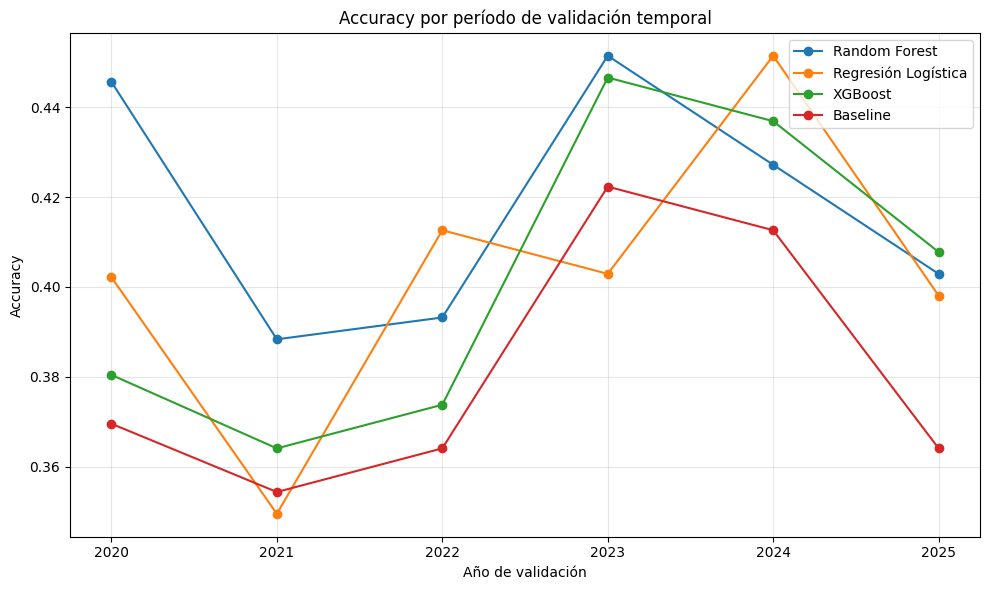

In [21]:
fig, ax = plt.subplots(
    figsize=(10, 6)
)

for modelo in (
    tabla_accuracy.columns
):

    ax.plot(
        tabla_accuracy.index,
        tabla_accuracy[modelo],
        marker="o",
        label=modelo
    )

ax.set_title(
    "Accuracy por período de validación temporal"
)

ax.set_xlabel(
    "Año de validación"
)

ax.set_ylabel(
    "Accuracy"
)

ax.legend()

ax.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "cv_temporal_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Celda 22 Gráfica F1 Macro temporal

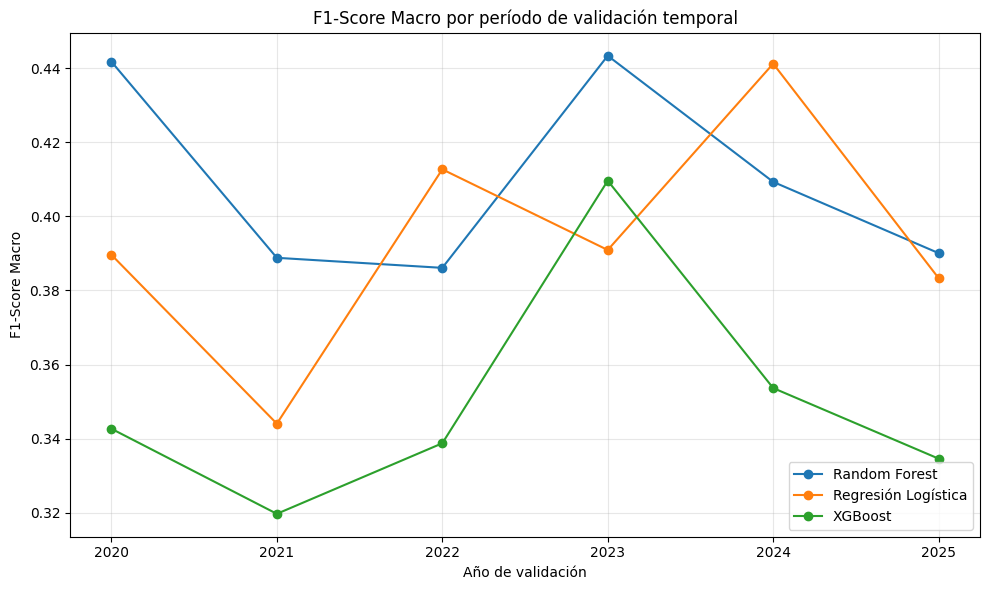

In [22]:
fig, ax = plt.subplots(
    figsize=(10, 6)
)

for modelo in (
    tabla_f1.columns
):

    ax.plot(
        tabla_f1.index,
        tabla_f1[modelo],
        marker="o",
        label=modelo
    )

ax.set_title(
    "F1-Score Macro por período de validación temporal"
)

ax.set_xlabel(
    "Año de validación"
)

ax.set_ylabel(
    "F1-Score Macro"
)

ax.legend()

ax.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "cv_temporal_f1_macro.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Celda 23 Resumen principal

In [25]:
resumen_cv_documento = (
    resumen_cv[
        [
            "modelo",
            "accuracy_media",
            "accuracy_std",
            "f1_media",
            "f1_std",
            "log_loss_media",
            "log_loss_std"
        ]
    ]
    .copy()
)

resumen_cv_documento.columns = [
    "Modelo",
    "Accuracy promedio",
    "SD Accuracy",
    "F1 Macro promedio",
    "SD F1",
    "Log Loss promedio",
    "SD Log Loss"
]

display(
    resumen_cv_documento.round(4)
)

,Modelo,Accuracy promedio,SD Accuracy,F1 Macro promedio,SD F1,Log Loss promedio,SD Log Loss
0,Random Forest,0.4181,0.0272,0.4099,0.0266,1.0779,0.0141
1,Regresión Logística,0.4028,0.0326,0.3936,0.0323,1.0891,0.0049
2,XGBoost,0.4016,0.0345,0.3499,0.0313,1.0823,0.0130


# Celda 24 Integrar baseline

In [24]:
baseline_resumen = (
    df_cv[
        [
            "anio_validacion",
            "baseline_accuracy"
        ]
    ]
    .drop_duplicates()
)

print(
    "Accuracy promedio del baseline:",
    round(
        baseline_resumen[
            "baseline_accuracy"
        ].mean(),
        4
    )
)

print(
    "Desviación estándar baseline:",
    round(
        baseline_resumen[
            "baseline_accuracy"
        ].std(),
        4
    )
)

Accuracy promedio del baseline: 0.3812
Desviación estándar baseline: 0.0287


# Celda 25 Ranking temporal

In [26]:
ranking_cv = pd.DataFrame({
    "Modelo": [
        "Random Forest",
        "Regresión Logística",
        "XGBoost"
    ],
    "Accuracy promedio": [
        resumen_cv.loc[
            resumen_cv["modelo"] == "Random Forest",
            "accuracy_media"
        ].iloc[0],

        resumen_cv.loc[
            resumen_cv["modelo"] == "Regresión Logística",
            "accuracy_media"
        ].iloc[0],

        resumen_cv.loc[
            resumen_cv["modelo"] == "XGBoost",
            "accuracy_media"
        ].iloc[0]
    ],
    "F1 Macro promedio": [
        resumen_cv.loc[
            resumen_cv["modelo"] == "Random Forest",
            "f1_media"
        ].iloc[0],

        resumen_cv.loc[
            resumen_cv["modelo"] == "Regresión Logística",
            "f1_media"
        ].iloc[0],

        resumen_cv.loc[
            resumen_cv["modelo"] == "XGBoost",
            "f1_media"
        ].iloc[0]
    ],
    "Folds sobre baseline": [
        6,
        4,
        6
    ]
})

ranking_cv["Ranking Accuracy"] = (
    ranking_cv[
        "Accuracy promedio"
    ]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)

ranking_cv["Ranking F1"] = (
    ranking_cv[
        "F1 Macro promedio"
    ]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)

display(
    ranking_cv.sort_values(
        "Ranking Accuracy"
    ).round(4)
)

,Modelo,Accuracy promedio,F1 Macro promedio,Folds sobre baseline,Ranking Accuracy,Ranking F1
0,Random Forest,0.4181,0.4099,6,1,1
1,Regresión Logística,0.4028,0.3936,4,2,2
2,XGBoost,0.4016,0.3499,6,3,3


## 5. Conclusión de la validación cruzada temporal
La validación temporal mostró que el desempeño de los modelos varía entre temporadas y que ningún resultado obtenido sobre un único período debe interpretarse de forma aislada.

Random Forest presentó el comportamiento histórico más consistente. Alcanzó el mayor Accuracy promedio y F1-Score Macro promedio entre los tres clasificadores, además de superar el baseline de cada período en los seis folds evaluados.
Regresión Logística presentó un comportamiento competitivo y obtuvo resultados particularmente favorables en determinadas temporadas, aunque no superó el baseline en todos los períodos.
XGBoost también superó el baseline en los seis folds, pero presentó un F1-Score Macro promedio inferior al de Regresión Logística y Random Forest. Esto indica que, aunque mantiene capacidad para superar una estrategia básica de clasificación, su comportamiento entre las tres clases fue menos equilibrado durante los períodos históricos analizados.

Estos resultados complementan, pero no sustituyen, la evaluación sobre el conjunto de prueba final. La validación cruzada temporal permite analizar la estabilidad histórica de los modelos, mientras que el conjunto de prueba de 2026 representa su comportamiento sobre el período cronológicamente más reciente reservado durante el desarrollo.